# Tax Support Question Router: Naive Bayes
**Report notebook (fully self-contained).** Routes a customer's tax question to a support queue and the best knowledge-base (KB) articles.

This notebook needs **no other files**. The data, the model code and the KB index are all inside it.
Only these packages are needed: `numpy`, `pandas`, `scipy`, `scikit-learn`, `matplotlib`.
Run all cells top to bottom (about 1 minute).

**Contents**
1. Problem and goal
2. Setup
3. Data
4. Preprocessing and features
5. Models: selection and comparison
6. Evaluation on held-out questions
7. Confidence threshold (when to defer to a human)
8. The router and inference demo
9. Online learning from agent corrections
10. Error analysis
11. Limitations and next steps

## 1. Problem and goal
Support agents read every incoming question and decide where it goes. Typical questions are
*"where is my refund"*, *"w2 upload not working"*, *"can I still file after April 15"*.

**Goal:** automate the first step.
1. **Classify** the question into one of 11 topics, each mapped to a support queue.
2. **Suggest** the top 3 KB articles for that topic.
3. **Defer** to a human when the model is not confident enough.

**Why Naive Bayes:** it trains in milliseconds, predicts in about 0.02 ms, is easy to explain (word counts per topic),
and supports online learning (`partial_fit`), so agent corrections can improve it live.

## 2. Setup

In [1]:
import json, copy, random, re, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import vstack
from sklearn.feature_extraction.text import HashingVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split
from sklearn.naive_bayes import ComplementNB, MultinomialNB

SEED = 42
TOP_K_ARTICLES = 3
pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# category -> support queue shown to the agent
CATEGORIES = {
    "refund_status": "Refunds & Amount Owed",
    "efile_pin": "E-File & Rejections",
    "w2_1099_import": "Document Import",
    "state_return": "State Returns",
    "deductions_credits": "Deductions & Credits",
    "self_employed": "Self-Employed & Gig",
    "investments_rental": "Investments, Crypto & Rental",
    "amended_return": "Amended Returns",
    "extension_deadline": "Deadlines & Extensions",
    "account_payment": "Account & Billing",
    "other_human": "Human Agent",
}
LABELS = list(CATEGORIES)
print(len(LABELS), "categories")

11 categories


## 3. Data
Three sources, none of them real customer data:

| Source | What | Size |
|---|---|---|
| Gold | Hand-written, casual questions in varied wording (cell below) | 110 |
| Synthetic | Questions generated from templates, with typos and filler words (cell below) | ~1,000 |
| KB index | Help-center pages (titles and URLs from olt.com; keywords are my own summaries) | 30 |

The long data cells are collapsed in JupyterLab. Click the cell to expand them.

**3.1 Gold questions** (hand-written, used for testing and a small part of training)

In [2]:
GOLD = {
    "refund_status": [
        "its been a month and still no refund what is going on",
        "irs says approved but money not in my bank",
        "how can i see where my federal refund is",
        "my refund came lower than the estimate olt showed me",
        "when do refunds usually hit the account after acceptance",
        "i owe money this year how do i pay it",
        "state refund still pending after 6 weeks",
        "need to know if the irs got my return and when i get paid",
        "refund check or direct deposit which is faster",
        "balance due on my return what are my options",
    ],
    "efile_pin": [
        "irs bounced my return with a reject code",
        "what pin do i type to sign my return",
        "dont remember last years agi cant submit",
        "return rejected because someone already claimed my kid",
        "how do i add my ip pin from the irs letter",
        "do i have to print and mail anything or is efile enough",
        "e-file failed with error ind-031",
        "can my spouse sign electronically too",
        "was my return transmitted successfully",
        "reject message says ssn does not match name",
    ],
    "w2_1099_import": [
        "tried uploading my w2 but nothing happens",
        "the scan picked up the wrong box 1 number",
        "can i just take a photo of my 1099 with my phone",
        "ai import missed my employers ein",
        "where on the w2 is the state wages box",
        "my employer has not sent a w-2 yet what can i do",
        "how do i bring in last years return",
        "pdf of my 1099-int will not read",
        "uploaded two w-2s but only one showed up",
        "what does code dd in box 12 mean",
    ],
    "state_return": [
        "do i pay extra for my state taxes",
        "i lived in two states last year how do i file",
        "can i only do the state and skip federal",
        "which states can i file in with olt",
        "california return got rejected",
        "i work in new jersey but live in new york need both returns",
        "how to file state when i moved mid year",
        "state tax form for ohio residents",
        "is there a cheaper way to add the state return",
        "state e-file status not showing",
    ],
    "deductions_credits": [
        "can i write off my work from home setup",
        "what is the standard deduction for single filer",
        "do i qualify for the earned income credit",
        "how do i claim the tips deduction",
        "overtime pay deduction where do i enter it",
        "should i itemize or take standard",
        "claiming my two kids child tax credit",
        "are my student loan payments deductible",
        "donations to church can i deduct them",
        "tuition 1098-t credit how to claim",
    ],
    "self_employed": [
        "i drive for uber how do i report that",
        "got a 1099-nec from a client what form do i use",
        "paypal sent me a 1099-k do i need to report it",
        "how is self employment tax figured",
        "can i deduct my laptop for my freelance work",
        "side business on etsy do i need schedule c",
        "doordash mileage how to deduct",
        "do i need to pay quarterly estimated taxes as a contractor",
        "i own a small llc how do i file",
        "business expenses i can write off as a freelancer",
    ],
    "investments_rental": [
        "i sold bitcoin this year how is it taxed",
        "where do i enter my 1099-b stock sales",
        "rental house depreciation how to calculate",
        "what is cost basis and where do i find it",
        "got a 1099-da from coinbase",
        "capital loss carryover from last year",
        "i rent out a room in my home how do i report income",
        "dividends from my brokerage account where to enter",
        "schedule e for two rental properties",
        "sold my shares at a loss can i deduct",
    ],
    "amended_return": [
        "i forgot a form after i already filed what now",
        "how do i fix an error on a return the irs accepted",
        "need to file a 1040-x",
        "can i amend a return from two years ago",
        "changed my mind about filing status after submitting",
        "how long until an amended return is processed",
        "i entered wrong income last year and filed already",
        "where do i check status of my amended return",
        "added a dependent late need to correct my return",
        "do i have to amend if the irs already sent a refund",
    ],
    "extension_deadline": [
        "when is the last day to file taxes",
        "need more time how do i get an extension",
        "i missed april 15 will there be a penalty",
        "does an extension give me more time to pay too",
        "can i still e-file in october",
        "form 4868 how do i submit it",
        "what happens if i file late",
        "is the deadline different this year",
        "last date to file without penalty",
        "extend my filing until october",
    ],
    "account_payment": [
        "i cant log in forgot my password",
        "was charged two times for my state return",
        "how much will i pay in total to file",
        "upgrade me to premium please",
        "i want my money back for premium",
        "change the email on my account",
        "do you have a promo code",
        "where can i find my previous year return",
        "cancel my subscription",
        "is the federal return really free or is there a catch",
    ],
    "other_human": [
        "i want to speak with a real person",
        "someone used my ssn to file a return",
        "got a letter from the irs about an audit",
        "received a cp2000 notice what do i do",
        "can you file taxes for my s corporation",
        "i need a lawyer for a tax dispute",
        "hello",
        "this is the worst service i want to file a complaint",
        "what is the weather today",
        "asdfgh qwerty",
    ],
}

**3.2 Synthetic questions.** Templates with fillable slots (for example `{state}`, `{kind}`), then noise: typos, dropped apostrophes,
and filler like "hi" or "pls help". The seed is fixed, so the data is the same on every run.

In [3]:
random.seed(7)

STATES = ["california", "new york", "texas", "ohio", "florida", "new jersey",
          "illinois", "georgia", "virginia", "pennsylvania", "massachusetts", "michigan"]
SLOTS = {
    "n": ["2", "3", "4", "5", "6", "8", "10"],
    "unit": ["weeks", "days"],
    "kind": ["federal", "state", "tax"],
    "irs": ["accepted", "approved", "processing", "received"],
    "code": ["IND-031-04", "IND-181", "R0000-500-01", "F8962-070", "IND-516"],
    "box": ["1", "2", "12", "14", "16", "17"],
    "state": STATES,
    "state2": STATES,
    "item": ["home office", "medical bills", "student loan interest", "charity donations",
             "property taxes", "daycare costs", "mortgage interest", "gifts", "moving costs",
             "work uniforms", "car registration", "tips income"],
    "platform": ["uber", "lyft", "doordash", "instacart", "etsy", "upwork", "fiverr", "airbnb"],
    "asset": ["bitcoin", "ethereum", "tesla stock", "mutual funds", "etf shares", "crypto", "options"],
    "yrs": ["1", "2", "3"],
    "form": ["1099-nec", "1099-k", "1099-b", "1099-int", "1099-div", "w-2", "1099-r", "1098"],
}

TEMPLATES = {
    "refund_status": [
        "where is my refund", "where is my {kind} refund", "how long does it take to get my {kind} refund",
        "my refund has not arrived after {n} {unit}", "check status of my tax refund",
        "irs shows {irs} but i have no refund yet", "when will my refund be deposited",
        "refund amount is different from the estimate", "why is my refund delayed",
        "how do i pay the amount i owe", "i owe taxes what are the payment options",
        "how to track my {kind} refund", "refund status says {irs} what does that mean",
        "still waiting on refund after {n} {unit}", "how do i see my refund date",
        "will the refund go to my bank account", "balance due how to pay irs",
    ],
    "efile_pin": [
        "my return was rejected by the irs", "efile rejection error {code}", "what is a self select pin",
        "i forgot my prior year agi", "how do i sign my return electronically",
        "irs rejected my return because my dependent was already claimed",
        "do i need to mail anything after e-filing", "was my return accepted by the irs",
        "how do i enter my identity protection pin", "return rejected code {code} how to fix",
        "how to resubmit a rejected return", "where do i find my ip pin",
        "does my spouse need a separate pin", "e-file not going through",
        "what does e-file reject mean", "how long does efile acceptance take",
    ],
    "w2_1099_import": [
        "w2 upload is not working", "how does the ai import work for w-2", "photo of my {form} failed to read",
        "import filled the wrong wages", "can i upload a pdf of my {form}",
        "employer id not detected after scanning", "where do i find box {box} on my w-2",
        "i do not have my w-2 yet", "how do i import last years return",
        "scan of my {form} is blurry what should i do", "import added the same {form} twice",
        "can i take a picture of my {form}", "ai import skipped my {form}",
        "how to manually enter my w-2 instead of upload", "w2 box {box} is missing after import",
        "upload says unsupported file type",
    ],
    "state_return": [
        "how much is a state return", "do i need to file a state return in {state}",
        "i moved from {state} to {state2} during the year how do i file",
        "can i file state only", "state refund status for {state}",
        "which states does olt support", "part year resident state filing",
        "{state} return was rejected", "is state filing an extra cost",
        "how do i add a state return", "do i have to file in {state} if i work remotely",
        "need to file two states {state} and {state2}", "where can i get {state} state tax forms",
        "when will my {state} refund come", "nonresident state return help",
    ],
    "deductions_credits": [
        "can i deduct {item}", "is {item} deductible", "standard deduction or itemized which is better",
        "how to claim the child tax credit", "am i eligible for the earned income credit",
        "how do i claim the new deduction for tips", "where do i enter overtime deduction",
        "how to claim education credit", "do i qualify for the american opportunity credit",
        "car loan interest deduction how does it work", "senior deduction how to claim",
        "how much is the child tax credit per kid", "what deductions am i missing",
        "can i claim my {item} on my return", "which credits do i qualify for",
        "how do i claim dependents for the child credit",
    ],
    "self_employed": [
        "how do i report freelance income", "do i need schedule c for my side business",
        "i received a {form} what do i do", "how to report {form} from {platform}",
        "how is self employment tax calculated", "{platform} driver tax deductions",
        "can i deduct business expenses", "i sell on {platform} how do i file",
        "do i pay estimated taxes as a contractor", "how to deduct mileage for {platform}",
        "sole proprietor tax filing help", "what business expenses can i write off",
        "i work as an independent contractor how do i file", "schedule se explained",
        "home office deduction for my freelance work",
    ],
    "investments_rental": [
        "how are {asset} gains taxed", "where do i enter {asset} sales", "how do i report rental income",
        "rental property depreciation help", "what is cost basis", "i received a 1099-da",
        "capital loss carryover", "how to report dividends", "schedule d for stock sales",
        "schedule e for rental properties", "i sold {asset} at a loss", "short term vs long term capital gains",
        "do i need to report {asset} trades", "rental expenses i can deduct",
        "where do i enter my brokerage 1099-b",
    ],
    "amended_return": [
        "i made a mistake on my filed return", "how do i file form 1040-x", "i forgot to include a {form} after filing",
        "can i amend my return from {yrs} years ago", "check amended return status",
        "i need to change my filing status after filing", "how long does an amended return take",
        "how to correct a return that was already accepted", "how do i amend my return with olt",
        "amend return to add a dependent", "i entered the wrong income and already filed",
        "do i have to amend my state return too", "can i amend electronically",
    ],
    "extension_deadline": [
        "what is the tax filing deadline", "how to file an extension form 4868",
        "i missed the deadline what now", "extension to file or extension to pay",
        "penalty for filing late", "can i still e-file after april 15",
        "how do i get more time to file", "when are taxes due this year",
        "do i owe a penalty if i file an extension", "last day to e-file",
        "file extension online for free", "how long is the extension",
    ],
    "account_payment": [
        "how much does olt cost", "is federal really free", "i was charged twice",
        "how do i pay for my state return", "i forgot my password and cannot sign in",
        "how to delete my account", "i want a refund of my payment", "how do i upgrade to premium",
        "update the email address on my account", "do you have a coupon code",
        "how to cancel premium", "where can i find my old return", "cannot log in to my account",
        "what payment methods do you accept", "unlock my account", "download a copy of my return",
    ],
    "other_human": [
        "i want to talk to a real person", "can someone call me back", "i think someone filed using my ssn",
        "i received an irs audit letter", "i got a cp2000 notice", "i need a tax lawyer",
        "can you file taxes for my s corp", "i want to file a complaint", "this service is terrible",
        "i need legal advice about my divorce and taxes", "hello", "hi", "test", "help",
        "what is the weather", "tell me a joke", "who are you", "asdfgh", "qwerty",
        "can i speak to a manager", "irs levied my bank account", "i need help with a payment plan with the irs",
    ],
}

PREFIX = ["", "", "", "hi ", "hello ", "pls help ", "urgent ", "quick question ", "hey team ", "need help ", "sir "]
SUFFIX = ["", "", "", " thanks", " please help", " ??", " asap", " pls", " thank you", " ?"]


def typo(word: str) -> str:
    if len(word) < 5:
        return word
    i = random.randrange(1, len(word) - 2)
    kind = random.choice(["swap", "drop", "dup"])
    if kind == "swap":
        return word[:i] + word[i + 1] + word[i] + word[i + 2:]
    if kind == "drop":
        return word[:i] + word[i + 1:]
    return word[:i] + word[i] + word[i:]


def noisy(text: str) -> str:
    words = text.split()
    words = [typo(w) if random.random() < 0.08 else w for w in words]
    text = " ".join(words)
    if random.random() < 0.4:
        text = text.replace("'", "")
    text = random.choice(PREFIX) + text + random.choice(SUFFIX)
    return text.strip()


def fill(template: str) -> str:
    out = template
    for key, values in SLOTS.items():
        token = "{" + key + "}"
        while token in out:
            out = out.replace(token, random.choice(values), 1)
    if "{state2}" in template:
        pass
    return out


def build_synthetic(per_template: int = 6):
    rows = set()
    for label, templates in TEMPLATES.items():
        for t in templates:
            for _ in range(per_template):
                rows.add((noisy(fill(t)), label))
    rows = sorted(rows)
    random.shuffle(rows)
    return rows

**3.3 KB index.** Each article belongs to one category. The `text` field holds my own short keyword summary, used for article ranking.

In [4]:
KB = [
 {
  "id": "kb-refund",
  "category": "refund_status",
  "title": "Refund Status or Amount Owed",
  "url": "https://kb.olt.com/KB/articles/refunds-or-amount-owed",
  "text": "check refund status where is my refund how long refund takes direct deposit irs accepted amount owed balance due how to pay taxes owed"
 },
 {
  "id": "kb-return-status",
  "category": "refund_status",
  "title": "Return Status",
  "url": "https://www.olt.com/main/home/returnstatus.php",
  "text": "return status accepted rejected pending irs state return acceptance tracking your e-filed return"
 },
 {
  "id": "kb-payment-owed",
  "category": "refund_status",
  "title": "Payment Options for Taxes Owed",
  "url": "https://www.olt.com/main/home/payment.php",
  "text": "pay irs balance due payment options direct debit installment owe taxes amount owed pay what i owe"
 },
 {
  "id": "kb-efile",
  "category": "efile_pin",
  "title": "E-Filing Guide and Self-Select PIN",
  "url": "https://kb.olt.com/KB/articles/e-filing-or-self-select-pin",
  "text": "e-file self select pin prior year agi sign return electronically rejected return identity protection pin ip pin rejection codes"
 },
 {
  "id": "kb-what-is-efile",
  "category": "efile_pin",
  "title": "What is E-File?",
  "url": "https://www.olt.com/main/home/whatisefile.php",
  "text": "what is e-file electronic filing irs authorized provider transmit return to irs accepted mail paper"
 },
 {
  "id": "kb-ai-import",
  "category": "w2_1099_import",
  "title": "AI Import for W-2 and 1099 Forms",
  "url": "https://www.olt.com/main/home/ai_marketing.php",
  "text": "ai import upload pdf photo w-2 1099 scan fills in income withholding employer details review before filing import prior year return"
 },
 {
  "id": "kb-w2",
  "category": "w2_1099_import",
  "title": "Understanding Form W-2",
  "url": "https://kb.olt.com/KB/articles/indiv_article_detail/form-w-2-2025-complete-guide",
  "text": "form w-2 boxes wages box 1 box 2 withholding box 12 codes box 14 employer ein where to find missing w-2"
 },
 {
  "id": "kb-1099int",
  "category": "w2_1099_import",
  "title": "Form 1099-INT: Reporting Interest Income",
  "url": "https://kb.olt.com/KB/articles/indiv_article_detail/form-1099-int-reporting-interest-income-guide",
  "text": "1099-int interest income bank statement report interest enter 1099 form"
 },
 {
  "id": "kb-states",
  "category": "state_return",
  "title": "State Tax Filing",
  "url": "https://www.olt.com/main/home/states.php",
  "text": "state return state tax filing supported states cost per state part-year resident moved nonresident state refund state only"
 },
 {
  "id": "kb-state-forms",
  "category": "state_return",
  "title": "State Forms",
  "url": "https://www.olt.com/main/home/statepub.php",
  "text": "state forms publications state tax forms download state income tax return"
 },
 {
  "id": "kb-deductions",
  "category": "deductions_credits",
  "title": "Tax Deductions Guide",
  "url": "https://kb.olt.com/KB/articles/tax-deductions",
  "text": "deductions guide home office medical expenses charity donations mortgage interest property taxes student loan interest what can i deduct"
 },
 {
  "id": "kb-std-vs-item",
  "category": "deductions_credits",
  "title": "Itemized vs Standard Deduction",
  "url": "https://kb.olt.com/KB/articles/article_detail/standard-vs-itemized-deduction-difference",
  "text": "standard deduction itemized deduction schedule a which is better difference"
 },
 {
  "id": "kb-credits",
  "category": "deductions_credits",
  "title": "Tax Credits Overview",
  "url": "https://kb.olt.com/KB/articles/credits",
  "text": "tax credits earned income credit eitc child care credit education credit american opportunity lifetime learning eligibility"
 },
 {
  "id": "kb-8812",
  "category": "deductions_credits",
  "title": "Schedule 8812: Child Tax Credit",
  "url": "https://kb.olt.com/KB/articles/indiv_article_detail/schedule-8812-2025-child-tax-credit-actc-odc-guide",
  "text": "child tax credit additional child tax credit dependents qualifying child credit for other dependents 2200 per child"
 },
 {
  "id": "kb-sched1a",
  "category": "deductions_credits",
  "title": "Schedule 1-A: New 2025 Deductions",
  "url": "https://kb.olt.com/KB/articles/indiv_article_detail/form-1040-schedule-1-a-guide-2025",
  "text": "schedule 1-a tips deduction overtime deduction car loan interest senior deduction new for 2025 qualified tips"
 },
 {
  "id": "kb-edu",
  "category": "deductions_credits",
  "title": "Education Credits and Deductions",
  "url": "https://kb.olt.com/KB/articles/education-credits-or-deductions",
  "text": "education credits students tuition 1098-t american opportunity lifetime learning student loan interest deduction"
 },
 {
  "id": "kb-selfemp",
  "category": "self_employed",
  "title": "Self-Employed and Freelancers",
  "url": "https://kb.olt.com/KB/articles/self-employed-and-freelancers",
  "text": "self employed freelancer schedule c schedule se self employment tax 1099-nec business income expenses home office estimated taxes"
 },
 {
  "id": "kb-gig",
  "category": "self_employed",
  "title": "Gig Workers",
  "url": "https://kb.olt.com/KB/articles/gig-workers",
  "text": "gig worker uber lyft doordash delivery driver 1099-k 1099-nec mileage deduction side hustle etsy paypal income"
 },
 {
  "id": "kb-gig-page",
  "category": "self_employed",
  "title": "Gig Economy Tax",
  "url": "https://www.olt.com/main/home/gig-economy-tax.php",
  "text": "gig economy tax rideshare freelance platform income reporting deductions"
 },
 {
  "id": "kb-business",
  "category": "self_employed",
  "title": "Business Taxes for Small Business Owners",
  "url": "https://kb.olt.com/KB/articles/business-taxes",
  "text": "small business owner schedule c business expenses sole proprietor deductions equipment supplies"
 },
 {
  "id": "kb-cg",
  "category": "investments_rental",
  "title": "Capital Gains or Losses",
  "url": "https://kb.olt.com/KB/articles/capital-gains-or-losses",
  "text": "capital gains losses stock sales schedule d 1099-b cryptocurrency crypto 1099-da cost basis dividends investments"
 },
 {
  "id": "kb-rental",
  "category": "investments_rental",
  "title": "Rental Property Income",
  "url": "https://kb.olt.com/KB/articles",
  "text": "rental property schedule e rental income depreciation landlord expenses repairs property"
 },
 {
  "id": "kb-amend",
  "category": "amended_return",
  "title": "Amended Returns",
  "url": "https://kb.olt.com/KB/articles/amended-returns",
  "text": "amended return form 1040-x correct mistake after filing forgot income change filing status amend previous year"
 },
 {
  "id": "kb-amend-page",
  "category": "amended_return",
  "title": "Amend a Return with OLT",
  "url": "https://www.olt.com/main/home/amended.php",
  "text": "amend return olt how to file an amended return status of amended return how long it takes"
 },
 {
  "id": "kb-extension",
  "category": "extension_deadline",
  "title": "Extension Filing",
  "url": "https://kb.olt.com/KB/articles/extension-filing",
  "text": "extension form 4868 file extension more time to file extension to pay late filing penalty"
 },
 {
  "id": "kb-deadlines",
  "category": "extension_deadline",
  "title": "Tax Deadlines",
  "url": "https://www.olt.com/main/home/taxdeadlines.php",
  "text": "tax deadline april 15 due date missed deadline file late penalty estimated tax dates"
 },
 {
  "id": "kb-pricing",
  "category": "account_payment",
  "title": "Can I File for Free?",
  "url": "https://www.olt.com/main/home/canusefree.php",
  "text": "free federal edition cost price state return 9.95 who can use free no hidden fees pricing"
 },
 {
  "id": "kb-premium",
  "category": "account_payment",
  "title": "Premium Edition",
  "url": "https://www.olt.com/main/home/canusepremium.php",
  "text": "premium edition upgrade phone chat support audit support priority processing price 7.95 cancel"
 },
 {
  "id": "kb-support",
  "category": "account_payment",
  "title": "Customer Service",
  "url": "https://www.olt.com/main/home/service.php",
  "text": "customer service contact support email phone chat sign in password reset account login charged twice billing refund payment"
 },
 {
  "id": "kb-continue",
  "category": "account_payment",
  "title": "Sign In and Continue Your Return",
  "url": "https://www.olt.com/main/home/continuereturn.php",
  "text": "sign in log in continue return forgot password username account access old return prior year return"
 }
]

**3.4 Build the datasets and split.**
Training = all synthetic + 60% of gold. **Test = the other 40% of gold (44 questions)**, never used for training.

In [5]:
syn = pd.DataFrame(build_synthetic(), columns=["text", "label"])
gold_rows = [(q, label) for label, qs in GOLD.items() for q in qs]
gold_df = pd.DataFrame(gold_rows, columns=["text", "label"])

g_train, g_test = train_test_split(gold_df, test_size=0.4, stratify=gold_df["label"], random_state=SEED)
train = pd.concat([syn, g_train], ignore_index=True)
gold = pd.concat([g_train, g_test], ignore_index=True)   # all gold, used for cross-validation

print(f"synthetic={len(syn)}  gold={len(gold)}  train={len(train)}  test={len(g_test)}  KB articles={len(KB)}")
syn.sample(8, random_state=1)

synthetic=1010  gold=110  train=1076  test=44  KB articles=30


,text,label
915,urgent where is my refund,refund_status
701,hi do i owe a penalty if i file an extension please help,extension_deadline
293,quick question do i need to file a state return in michigan ??,state_return
507,quick question how to correct a return that was already accepted,amended_return
970,quick question schedule se explained,self_employed
248,urgent amend return to add a dependent thank you,amended_return
719,hey team hello ??,other_human
910,import added the same 1099-nec twice ?,w2_1099_import


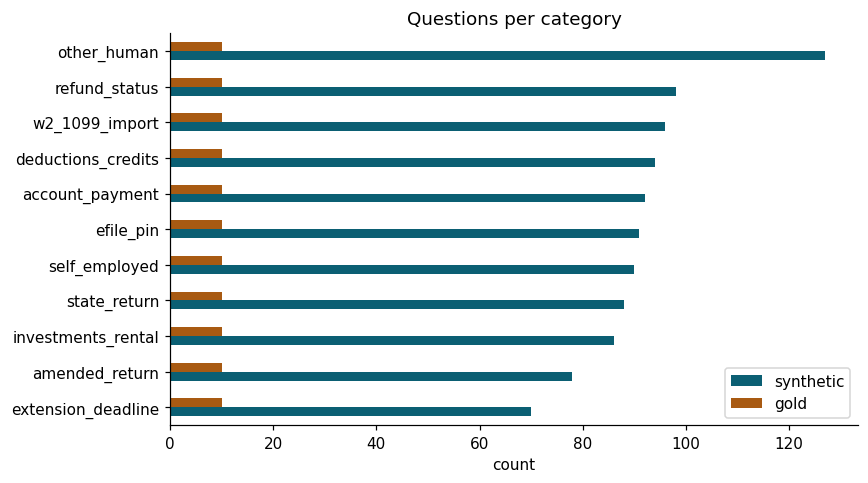

In [6]:
counts = pd.DataFrame({"synthetic": syn.label.value_counts(), "gold": gold.label.value_counts()}).fillna(0).astype(int)
counts = counts.sort_values("synthetic")
ax = counts.plot.barh(figsize=(8, 4.5), color=["#0B5F73", "#A85A12"])
ax.set_title("Questions per category"); ax.set_xlabel("count"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

## 4. Preprocessing and features
**Cleaning (`clean`)** lowercases, removes symbols and **masks personal data** (SSN, email, phone) so it never reaches the model or any log.

**Features (`HashingVectorizer`)** turn text into numbers. Every word and word pair (1-2 grams) is hashed into one of 65,536 slots.
A fixed feature space is what makes online learning (`partial_fit`) possible. A normal vocabulary would change when new words appear.

In [7]:
_PII = [
    (re.compile(r"\b\d{3}-\d{2}-\d{4}\b"), " ssnredacted "),
    (re.compile(r"\b\d{9}\b"), " numredacted "),
    (re.compile(r"[\w.+-]+@[\w-]+\.[\w.]+"), " emailredacted "),
    (re.compile(r"\b\d{3}[-.\s]\d{3}[-.\s]\d{4}\b"), " phoneredacted "),
]

def clean(text: str) -> str:
    """Mask PII, lowercase, strip symbols."""
    text = text.strip()
    for pattern, repl in _PII:
        text = pattern.sub(repl, text)
    text = text.lower()
    text = re.sub(r"[^a-z0-9\-\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

def make_vectorizer() -> HashingVectorizer:
    return HashingVectorizer(n_features=2 ** 16, ngram_range=(1, 2), alternate_sign=False,
                             norm="l2", token_pattern=r"(?u)\b[\w-]+\b")

def feats(vec, texts):
    return vec.transform([clean(t) for t in texts])

for e in ["My SSN is 123-45-6789, where is my refund??", "Email me at jane@mail.com pls!!", "W2 box-12 code DD ???"]:
    print(f"{e!r}\n   -> {clean(e)!r}")

vec = make_vectorizer()
x = vec.transform([clean("my refund has not come after 5 weeks")])
print("\nfeature matrix shape:", x.shape, "| non-zero features for this question:", x.nnz)

'My SSN is 123-45-6789, where is my refund??'
   -> 'my ssn is ssnredacted where is my refund'
'Email me at jane@mail.com pls!!'
   -> 'email me at emailredacted pls'
'W2 box-12 code DD ???'
   -> 'w2 box-12 code dd'

feature matrix shape: (1, 65536) | non-zero features for this question: 15


## 5. Models: selection and comparison
Candidates, all on the same features:
- **MultinomialNB**: classic Naive Bayes on word counts.
- **ComplementNB**: Naive Bayes that learns from what each topic is *not*. Usually better with unequal class sizes.
- **Logistic Regression**: a stronger, slower baseline.

The hand-written set is small, so a single split is noisy. I therefore use **repeated cross-validation over all 110 gold questions**
(the synthetic data is always in training) both to pick the Naive Bayes variant and smoothing (`alpha`), and to compare against Logistic Regression.

In [8]:
Xs, Xg = feats(vec, syn.text), feats(vec, gold.text)
ys, yg = syn.label.values, gold.label.values

def cv_scores(make_model, n_splits=5, n_repeats=5, seed=1):
    cv = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=seed)
    out = []
    for tr, va in cv.split(Xg, yg):
        m = make_model().fit(vstack([Xs, Xg[tr]]), np.r_[ys, yg[tr]])
        out.append(f1_score(yg[va], m.predict(Xg[va]), average="macro"))
    return np.array(out)

NB_VARIANTS = {"MultinomialNB": MultinomialNB, "ComplementNB": ComplementNB}
ALPHAS = [0.01, 0.03, 0.05, 0.1, 0.3, 1.0]

grid = {}
for name, cls in NB_VARIANTS.items():
    for a in ALPHAS:
        grid[(name, a)] = cv_scores(lambda: cls(alpha=a), n_splits=4, n_repeats=5, seed=SEED).mean()

grid_df = pd.Series(grid).unstack().round(3)
display(grid_df)

variant, alpha = max(grid, key=grid.get)
print(f"selected by cross-validation: {variant}, alpha={alpha}")

,0.01,0.03,0.05,0.10,0.30,1.00
ComplementNB,0.813,0.822,0.822,0.830,0.850,0.822
MultinomialNB,0.808,0.796,0.794,0.798,0.804,0.787


selected by cross-validation: ComplementNB, alpha=0.3


,macro-F1 mean,std
MultinomialNB (a=0.01),0.809,0.067
ComplementNB (a=0.3),0.849,0.070
LogisticRegression,0.823,0.079


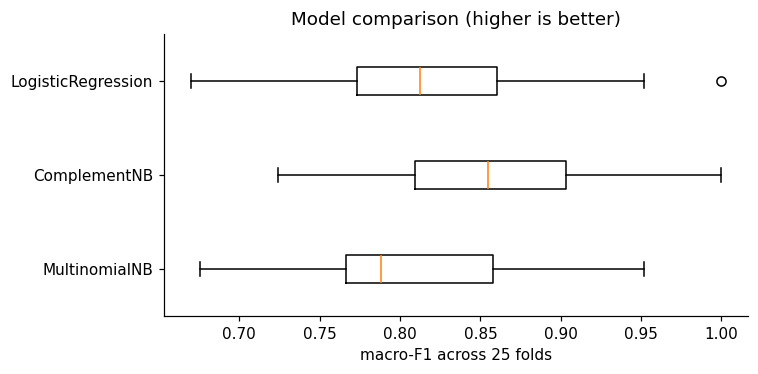

In [9]:
best_multi_alpha = max(ALPHAS, key=lambda a: grid[("MultinomialNB", a)])
candidates = {
    f"MultinomialNB (a={best_multi_alpha})": lambda: MultinomialNB(alpha=best_multi_alpha),
    f"{variant} (a={alpha})": lambda: NB_VARIANTS[variant](alpha=alpha),
    "LogisticRegression": lambda: LogisticRegression(max_iter=2000, C=10),
}
# keep the list unique if the selected variant is MultinomialNB
scores = {k: cv_scores(f) for k, f in candidates.items()}

summary = pd.DataFrame({k: {"macro-F1 mean": v.mean(), "std": v.std()} for k, v in scores.items()}).T.round(3)
display(summary)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.boxplot(list(scores.values()), labels=[k.split(" ")[0] for k in scores], vert=False)
ax.set_xlabel("macro-F1 across 25 folds"); ax.set_title("Model comparison (higher is better)")
plt.tight_layout(); plt.show()

**Reading this.** The spread between folds (std about 0.07) is bigger than the gaps between models, so
**the differences are within noise**. A fair claim is "Naive Bayes is competitive with Logistic Regression here while being
simpler and faster", not "Naive Bayes wins".

## 6. Evaluation on held-out questions
Train the selected model on the training set and score it on the 44 held-out questions.
It is trained with `partial_fit`, which gives the same result as `fit` for Naive Bayes and keeps online updates possible later.

In [10]:
Xtr, ytr = feats(vec, train.text), train.label.values
Xte, yte = feats(vec, g_test.text), g_test.label.values

served = NB_VARIANTS[variant](alpha=alpha)
served.partial_fit(Xtr, ytr, classes=LABELS)

pred = served.predict(Xte)
print(f"served model: {variant} (alpha={alpha})")
print(f"accuracy = {accuracy_score(yte, pred):.3f}   macro-F1 = {f1_score(yte, pred, average='macro'):.3f}\n")
print(classification_report(yte, pred, zero_division=0))

served model: ComplementNB (alpha=0.3)
accuracy = 0.886   macro-F1 = 0.887

                    precision    recall  f1-score   support

   account_payment       1.00      0.75      0.86         4
    amended_return       0.80      1.00      0.89         4
deductions_credits       1.00      1.00      1.00         4
         efile_pin       1.00      1.00      1.00         4
extension_deadline       1.00      0.75      0.86         4
investments_rental       1.00      0.75      0.86         4
       other_human       0.67      1.00      0.80         4
     refund_status       1.00      0.75      0.86         4
     self_employed       0.75      0.75      0.75         4
      state_return       0.80      1.00      0.89         4
    w2_1099_import       1.00      1.00      1.00         4

          accuracy                           0.89        44
         macro avg       0.91      0.89      0.89        44
      weighted avg       0.91      0.89      0.89        44



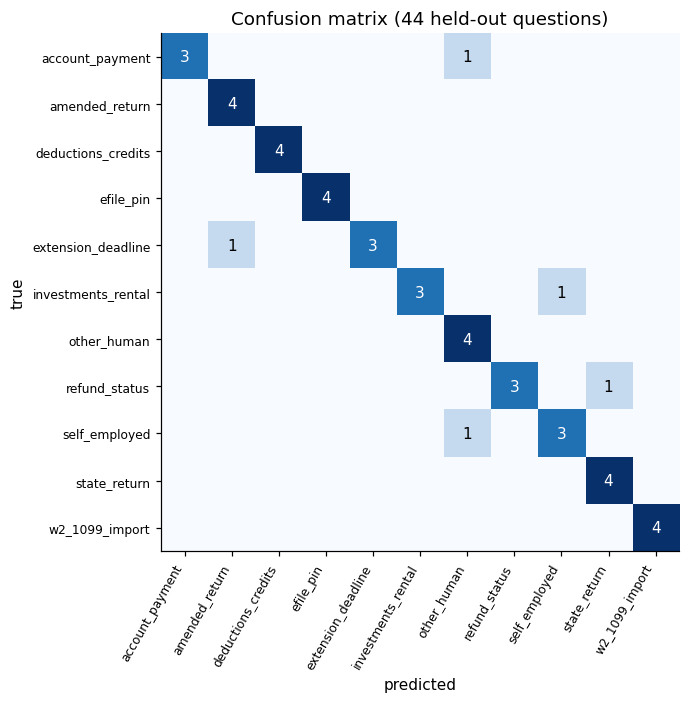

In [11]:
labels = sorted(LABELS)
cm = confusion_matrix(yte, pred, labels=labels)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(labels))); ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=60, ha="right", fontsize=8); ax.set_yticklabels(labels, fontsize=8)
for i in range(len(labels)):
    for j in range(len(labels)):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Confusion matrix (44 held-out questions)")
plt.tight_layout(); plt.show()

## 7. Confidence threshold: when to defer to a human
A wrong auto-route is worse than a slow reply, so the router only auto-routes when the top probability is above a line.
Below it, the question goes to a person.

To choose the line without cheating, I use **out-of-fold predictions**: every gold question is predicted by a model that
never saw it. For each threshold I check how many questions are auto-routed (**coverage**) and how many of those are correct (**accuracy**).

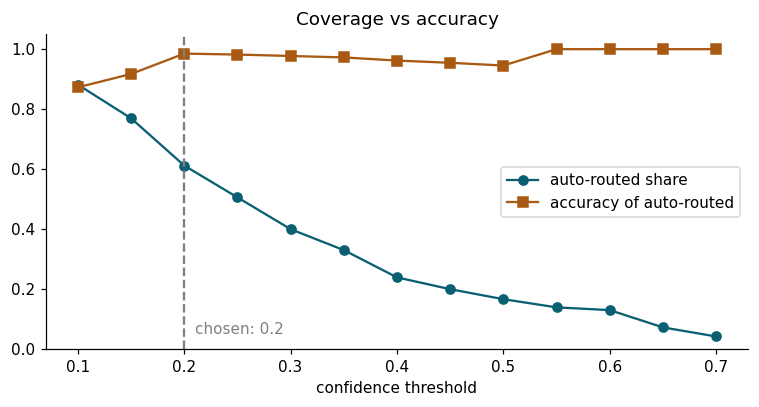

,threshold,auto_routed,accuracy_when_auto
0,0.10,0.882,0.873
1,0.15,0.770,0.917
2,0.20,0.612,0.985
3,0.25,0.506,0.982
4,0.30,0.400,0.977
5,0.35,0.330,0.972
6,0.40,0.239,0.962
7,0.45,0.200,0.955
8,0.50,0.167,0.945
9,0.55,0.139,1.000


In [12]:
conf_l, pred_l, true_l = [], [], []
for tr, va in RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED).split(Xg, yg):
    m = NB_VARIANTS[variant](alpha=alpha).fit(vstack([Xs, Xg[tr]]), np.r_[ys, yg[tr]])
    p = m.predict_proba(Xg[va])
    conf_l += list(p.max(axis=1)); pred_l += list(m.classes_[p.argmax(axis=1)]); true_l += list(yg[va])
conf, pr, tr_ = np.array(conf_l), np.array(pred_l), np.array(true_l)

rows = []
for th in np.arange(0.10, 0.75, 0.05):
    keep = (conf >= th) & (pr != "other_human")
    rows.append({"threshold": round(th, 2), "auto_routed": keep.mean(),
                 "accuracy_when_auto": (pr[keep] == tr_[keep]).mean() if keep.any() else np.nan})
trade = pd.DataFrame(rows)

CONFIDENCE_THRESHOLD = 0.20   # chosen from the table below

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(trade.threshold, trade.auto_routed, marker="o", label="auto-routed share", color="#0B5F73")
ax.plot(trade.threshold, trade.accuracy_when_auto, marker="s", label="accuracy of auto-routed", color="#A85A12")
ax.axvline(CONFIDENCE_THRESHOLD, color="gray", ls="--")
ax.text(CONFIDENCE_THRESHOLD + 0.01, 0.05, f"chosen: {CONFIDENCE_THRESHOLD}", color="gray")
ax.set_xlabel("confidence threshold"); ax.set_ylim(0, 1.05); ax.legend(loc="center right"); ax.set_title("Coverage vs accuracy")
plt.tight_layout(); plt.show()
trade.round(3)

**Reading this.** A higher line makes the router safer but sends more questions to people. At the chosen **0.20**,
roughly 6 in 10 questions auto-route at about 98% accuracy.

**Note:** ComplementNB probabilities are flat (with 11 classes, pure chance is 0.09), so treat the confidence as a *ranking score*, not a literal probability.

## 8. The router and inference demo
`Router.classify()` runs the full pipeline: clean, vectorize, predict, apply the threshold, then pick articles.
Article choice is TF-IDF similarity between the question and the KB articles, **inside the predicted category only**.

In [13]:
class Router:
    def __init__(self, clf, kb, vec):
        self.clf, self.kb, self.vec = clf, kb, vec
        self._kb_vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, stop_words="english")
        self._kb_matrix = self._kb_vec.fit_transform([f'{a["title"]} {a["title"]} {a["text"]}' for a in kb])

    def articles_for(self, text, category, k=TOP_K_ARTICLES):
        idx = [i for i, a in enumerate(self.kb) if a["category"] == category]
        if not idx:
            return []
        q = self._kb_vec.transform([clean(text)])
        sims = (self._kb_matrix[idx] @ q.T).toarray().ravel()
        return [{"title": self.kb[idx[i]]["title"], "url": self.kb[idx[i]]["url"], "score": round(float(sims[i]), 3)}
                for i in np.argsort(-sims)[:k]]

    def classify(self, text):
        proba = self.clf.predict_proba(self.vec.transform([clean(text)]))[0]
        order = np.argsort(-proba)
        classes = list(self.clf.classes_)
        top, conf = classes[order[0]], float(proba[order[0]])
        auto = conf >= CONFIDENCE_THRESHOLD and top != "other_human"
        return {
            "category": top, "confidence": round(conf, 3),
            "queue": CATEGORIES[top if auto else "other_human"],
            "decision": "auto_route" if auto else "human_review",
            "alternatives": [{"category": classes[i], "confidence": round(float(proba[i]), 3)} for i in order[1:3]],
            "top_articles": self.articles_for(text, top) if auto else [],
        }

    def learn(self, text, label):
        """Online learning: update the model with one corrected example."""
        assert label in LABELS, f"unknown label: {label}"
        self.clf.partial_fit(self.vec.transform([clean(text)]), [label])

router = Router(served, KB, vec)

tests = [
    "my refund has not come after 5 weeks",
    "w2 photo upload keeps failing",
    "irs rejected my return code IND-031",
    "i sold bitcoin how do i report it",
    "can i still file after april 15",
    "uber driver mileage deduction",
    "hello",
    "my ssn 123-45-6789 return rejected",
]
rows = []
for q in tests:
    r = router.classify(q)
    rows.append({"question": q, "predicted": r["category"], "confidence": r["confidence"], "decision": r["decision"],
                 "queue": r["queue"], "top article": r["top_articles"][0]["title"] if r["top_articles"] else "-"})
pd.DataFrame(rows)

,question,predicted,confidence,decision,queue,top article
0,my refund has not come after 5 weeks,refund_status,0.711,auto_route,Refunds & Amount Owed,Refund Status or Amount Owed
1,w2 photo upload keeps failing,w2_1099_import,0.545,auto_route,Document Import,AI Import for W-2 and 1099 Forms
2,irs rejected my return code IND-031,efile_pin,0.446,auto_route,E-File & Rejections,E-Filing Guide and Self-Select PIN
3,i sold bitcoin how do i report it,investments_rental,0.286,auto_route,"Investments, Crypto & Rental",Capital Gains or Losses
4,can i still file after april 15,extension_deadline,0.528,auto_route,Deadlines & Extensions,Tax Deadlines
5,uber driver mileage deduction,self_employed,0.444,auto_route,Self-Employed & Gig,Gig Workers
6,hello,other_human,0.123,human_review,Human Agent,-
7,my ssn 123-45-6789 return rejected,other_human,0.218,human_review,Human Agent,-


### Why did it pick that? (word-level view)
Naive Bayes is explainable: each word leans toward some topics. Scoring each word on its own shows what drove the decision.

In [14]:
def explain(text):
    out = []
    for w in clean(text).split():
        p = router.clf.predict_proba(router.vec.transform([w]))[0]
        out.append({"word": w, "leans toward": router.clf.classes_[p.argmax()], "strength": round(float(p.max()), 2)})
    return pd.DataFrame(out)

explain("my refund has not come after 5 weeks")

,word,leans toward,strength
0,my,account_payment,0.10
1,refund,refund_status,0.37
2,has,refund_status,0.25
3,not,w2_1099_import,0.20
4,come,state_return,0.38
5,after,amended_return,0.11
6,5,refund_status,0.16
7,weeks,refund_status,0.34


Single words are noisy (for example "not" may lean to an unrelated topic). The signal comes from the strong words ("refund", "weeks"), and Naive Bayes combines all of them.

Also note that the last demo question above, which contains an SSN, may be sent to a human: the masked token (`ssnredacted`) carries no topic signal, so confidence drops.
That is a safe failure, and a reason to mask PII *and* keep the human fallback.

## 9. Online learning from agent corrections
When the model is wrong, an agent picks the right queue. `Router.learn()` calls `partial_fit`, so the model updates immediately.
Here I work on a copy of the model so the rest of the notebook is unaffected.

In [15]:
demo = Router(copy.deepcopy(served), KB, vec)
q = "how do i file a 1040-x"

b = demo.classify(q)
print(f"before: {b['category']:<16} confidence={b['confidence']}  decision={b['decision']}")
for _ in range(3):
    demo.learn(q, "amended_return")
a = demo.classify(q)
print(f"after : {a['category']:<16} confidence={a['confidence']}  decision={a['decision']}")

before: amended_return   confidence=0.153  decision=human_review
after : amended_return   confidence=0.267  decision=auto_route


## 10. Error analysis
Which held-out questions did the model get wrong, and what would the safety rule have done with them?

In [16]:
proba = served.predict_proba(Xte)
err = pd.DataFrame({"question": g_test.text.values, "true": yte, "predicted": pred, "confidence": proba.max(axis=1).round(2)})
wrong = err[err.true != err.predicted].copy()
wrong["decision"] = np.where((wrong.confidence >= CONFIDENCE_THRESHOLD) & (wrong.predicted != "other_human"), "auto_route", "human_review")
print(f"{len(wrong)} errors out of {len(err)} | auto-routed wrongly: {(wrong.decision == 'auto_route').sum()} | caught by the safety rule: {(wrong.decision == 'human_review').sum()}")
wrong.reset_index(drop=True)

5 errors out of 44 | auto-routed wrongly: 0 | caught by the safety rule: 5


,question,true,predicted,confidence,decision
0,i rent out a room in my home how do i report income,investments_rental,self_employed,0.15,human_review
1,got a 1099-nec from a client what form do i use,self_employed,other_human,0.16,human_review
2,need to know if the irs got my return and when i get paid,refund_status,state_return,0.14,human_review
3,extend my filing until october,extension_deadline,amended_return,0.17,human_review
4,i want my money back for premium,account_payment,other_human,0.21,human_review


**What the errors show.**
- Some are neighbouring-topic mix-ups (for example renting out a room vs self-employed income, or refund status vs state refunds). These topics share words, and Naive Bayes only counts words, so it cannot tell which meaning is intended.
- Others fall into the `other_human` catch-all.
- In this run **all errors had low confidence**, so the threshold rule sends them to a person instead of routing them wrongly.

This is only 44 questions, so it shows the idea works, not that it is guaranteed on real traffic.

## 11. Limitations and next steps
**Limitations (be upfront about these)**
- Training data is mostly **synthetic**, so it is cleaner than real customer text.
- The test set is **small (44 questions)**. Model gaps are within noise (section 5).
- The model variant was chosen with cross-validation over all gold questions, and the held-out split was seen during development, so the headline score is **somewhat optimistic**.
- KB article text is **my own keyword summaries**, not the real article bodies. Retrieval quality is unproven.
- Confidence is a ranking score, not a calibrated probability.

**Next steps (extension work)**
1. Collect real public phrasing (r/tax, r/taxhelp via the official API) and label 300+ questions as a proper test set.
2. Replace KB summaries with real article text (check robots.txt and terms, or get permission).
3. Add non-English and Tanglish phrasing, and a seasonal test (January vs April topics).
4. Compare with a small transformer (DistilBERT) for the cost-versus-accuracy story.
5. Deploy (Render / HF Spaces) with a live metrics panel.